In [1]:
!pip -q install openai pandas numpy matplotlib seaborn scikit-learn

In [2]:
# Import Libraries & Load Dataset
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from openai import OpenAI

iris = load_iris(as_frame=True)
df = iris.frame.copy()

df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)
df = df.drop(columns=["target"])

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [20]:
# Set Up AI Client
from openai import OpenAI
from getpass import getpass

# Clear previous AI client
client = None

# Enter Gemini API key securely
api_key = getpass("Enter your Gemini API key: ").strip()

# Create Gemini AI client
client = OpenAI(
    api_key=api_key,
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/"
)

# Select free-tier AI model
MODEL = "gemini-3.5-flash-lite"

print("Gemini AI Client Configured Successfully!")

Enter your Gemini API key: ··········
Gemini AI Client Configured Successfully!


In [21]:
# Test Gemini API Connection
try:
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "user", "content": "Hello"}
        ]
    )

    print("Connection Successful!")
    print(response.choices[0].message.content)

except Exception as error:
    print("Error Type:", type(error).__name__)
    print("Error Details:", str(error))

Connection Successful!
Hello! How can I help you today?


In [22]:
# Creating EDA Tools
def dataset_summary():
    return {
        "rows": len(df),
        "columns": df.columns.tolist(),
        "statistics": df.describe().round(3).to_dict(),
        "species_counts": df["species"].value_counts().to_dict()
    }

def missing_values():
    return df.isna().sum().to_dict()

def correlations():
    return (
        df.select_dtypes(include="number")
        .corr()
        .round(3)
        .to_dict()
    )

def create_chart(chart_type):
    if chart_type == "species_count":
        sns.countplot(data=df, x="species")
        plt.title("Flower Count by Species")

    elif chart_type == "petal_scatter":
        sns.scatterplot(
            data=df,
            x="petal length (cm)",
            y="petal width (cm)",
            hue="species"
        )
        plt.title("Petal Length vs. Petal Width")

    elif chart_type == "correlation":
        sns.heatmap(
            df.select_dtypes(include="number").corr(),
            annot=True,
            cmap="coolwarm"
        )
        plt.title("Feature Correlations")

    else:
        return {"error": "Unsupported chart type"}

    plt.tight_layout()
    plt.show()

    return {"status": "Chart displayed", "chart_type": chart_type}

In [23]:
# Register Tools With Agent
tools = [
    {
        "type": "function",
        "function": {
            "name": "dataset_summary",
            "description": "Get dataset size, statistics, and species counts.",
            "parameters": {
                "type": "object",
                "properties": {},
                "additionalProperties": False
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "missing_values",
            "description": "Count missing values in each column.",
            "parameters": {
                "type": "object",
                "properties": {},
                "additionalProperties": False
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "correlations",
            "description": "Calculate correlations between numeric features.",
            "parameters": {
                "type": "object",
                "properties": {},
                "additionalProperties": False
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "create_chart",
            "description": "Create a chart for the Iris dataset.",
            "parameters": {
                "type": "object",
                "properties": {
                    "chart_type": {
                        "type": "string",
                        "enum": [
                            "species_count",
                            "petal_scatter",
                            "correlation"
                        ]
                    }
                },
                "required": ["chart_type"],
                "additionalProperties": False
            }
        }
    }
]

In [26]:
# Create AI Agent
import json

tool_functions = {
    "dataset_summary": dataset_summary,
    "missing_values": missing_values,
    "correlations": correlations,
    "create_chart": create_chart
}

def ask_agent(question):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an AI data analysis agent. "
                "Use the available tools to analyze the Iris dataset. "
                "Always use tools to support your findings. "
                "Explain results in simple English. "
                "Do not invent results."
            )
        },
        {
            "role": "user",
            "content": question
        }
    ]

    print("User Question:", question)
    print("-" * 60)

    # Limit agent iterations
    for step in range(5):
        response = client.chat.completions.create(
            model=MODEL,
            messages=messages,
            tools=tools,
            tool_choice="auto"
        )

        message = response.choices[0].message

        # Preserve the full Gemini response and thought signatures
        messages.append(message.model_dump(exclude_none=True))

        # Display final AI response
        if not message.tool_calls:
            print("\nAI Agent Findings:")
            print(message.content or "No response.")
            return

        # Execute selected tools
        for call in message.tool_calls:
            name = call.function.name
            print("Agent selected:", name)

            try:
                args = json.loads(call.function.arguments)

                if name in tool_functions:
                    result = tool_functions[name](**args)
                else:
                    result = {"error": "Unknown tool"}

            except Exception as error:
                result = {"error": str(error)}

            # Return tool results to Gemini
            messages.append({
                "role": "tool",
                "tool_call_id": call.id,
                "name": name,
                "content": json.dumps(result, default=str)
            })

    print("Agent Reached The Tool-Call Limit.")

In [27]:
# Ask Agent To Explore Dataset
ask_agent(
    "Explore the Iris dataset. Tell me its size, "
    "main features, and any missing values."
)

User Question: Explore the Iris dataset. Tell me its size, main features, and any missing values.
------------------------------------------------------------
Agent selected: dataset_summary
Agent selected: missing_values

AI Agent Findings:
Here is an overview of the Iris dataset based on the data analysis:

### 1. Dataset Size
* **Total Rows (Samples):** 150
* **Total Columns (Features + Species):** 5
* **Species breakdown:** Exactly 50 samples for each of the three species:
  * `setosa` (50)
  * `versicolor` (50)
  * `virginica` (50)

---

### 2. Main Features & Statistics
The dataset measures four numeric features for each flower (all measured in centimeters):
* **Sepal Length:** 
  * Mean: 5.84 cm (Range: 4.30 cm to 7.90 cm)
* **Sepal Width:** 
  * Mean: 3.06 cm (Range: 2.00 cm to 4.40 cm)
* **Petal Length:** 
  * Mean: 3.76 cm (Range: 1.00 cm to 6.90 cm)
* **Petal Width:** 
  * Mean: 1.20 cm (Range: 0.10 cm to 2.50 cm)

---

### 3. Missing Values
* **Missing values count:** **0**

In [28]:
# Ask About Relationships
ask_agent(
    "Which numerical features have the strongest "
    "relationships? Use the correlation tool."
)

User Question: Which numerical features have the strongest relationships? Use the correlation tool.
------------------------------------------------------------
Agent selected: correlations

AI Agent Findings:
Based on the correlation analysis of the numerical features in the Iris dataset, the strongest relationship is between **petal length (cm)** and **petal width (cm)**, with a very high positive correlation of **0.963**. 

Other strong relationships include:
* **Petal length** and **Sepal length**: **0.872**
* **Petal width** and **Sepal length**: **0.818**

In contrast, **sepal width** shows weak or slightly negative correlations with the other features (for example, -0.428 with petal length).


User Question: Create a scatter plot of petal length and petal width, then explain what it shows.
------------------------------------------------------------
Agent selected: create_chart


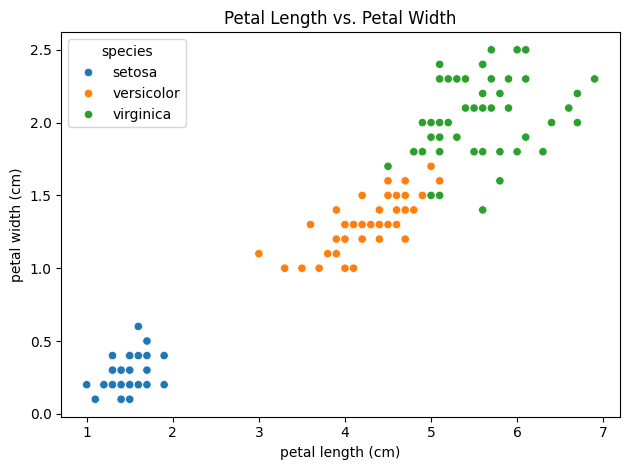

Agent selected: correlations

AI Agent Findings:
I have successfully created the scatter plot of petal length versus petal width. 

### What the chart shows:
1. **Strong Positive Relationship:** There is a very strong positive correlation (approximately **0.96**) between petal length and petal width. As the petal length increases, the petal width almost always increases as well.
2. **Clear Grouping (Species Separation):** 
   - **Setosa** flowers form a distinct, compact cluster at the bottom left with very small petals (short length and narrow width).
   - **Versicolor** and **Virginica** flowers have larger petals and form separate groups further up the trend, though they sit closer to each other along the continuum.

This relationship makes petal dimensions one of the most reliable features for distinguishing between the different Iris species!


In [29]:
# Visualizations

ask_agent(
    "Create a scatter plot of petal length and "
    "petal width, then explain what it shows."
)

User Question: Create a chart showing how many flowers belong to each species.
------------------------------------------------------------
Agent selected: create_chart


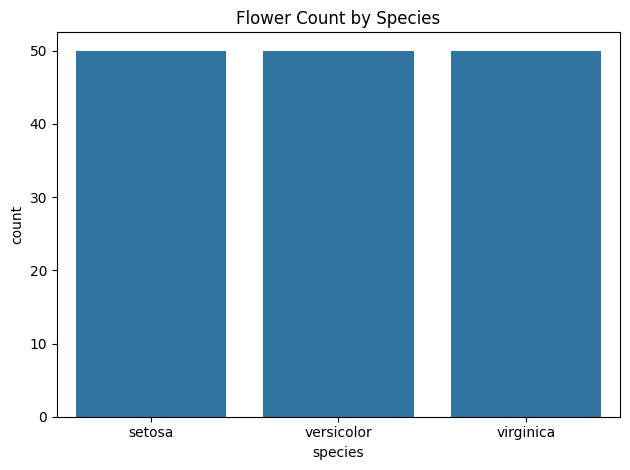


AI Agent Findings:
I have created a chart showing the number of flowers for each species in the Iris dataset. As you can see, the dataset is balanced, containing an equal number of flowers (50 each) for the three species: *Setosa*, *Versicolor*, and *Virginica*.


In [30]:
# Generate Chart

ask_agent(
    "Create a chart showing how many flowers "
    "belong to each species."
)

In [31]:
# Ask For Final Explanation

ask_agent(
    "Summarize the important findings from "
    "the dataset in simple language. Use "
    "the available tools to support your answer."
)

User Question: Summarize the important findings from the dataset in simple language. Use the available tools to support your answer.
------------------------------------------------------------
Agent selected: dataset_summary
Agent selected: missing_values
Agent selected: correlations

AI Agent Findings:
Here is a simple summary of the important findings from the Iris dataset:

1. **Dataset Size & Balance**: 
   - The dataset contains **150 total samples** of iris flowers with **no missing values**.
   - It is perfectly balanced across **3 different species** (*setosa*, *versicolor*, and *virginica*), with exactly **50 samples for each species**.

2. **Flower Measurements**:
   - **Sepal Length**: Averages about 5.84 cm (ranging from 4.3 cm to 7.9 cm).
   - **Sepal Width**: Averages about 3.06 cm (ranging from 2.0 cm to 4.4 cm).
   - **Petal Length**: Averages about 3.76 cm (ranging from 1.0 cm to 6.9 cm).
   - **Petal Width**: Averages about 1.20 cm (ranging from 0.1 cm to 2.5 cm).

3

## Project Conclusion

I created an AI agent using Google Gemini to explore and analyze the Iris dataset.

The AI agent was able to:

- Identify the size and features of the dataset.
- Check for missing values.
- Generate summary statistics.
- Find relationships between features.
- Create charts and visualizations.
- Explain important findings.

The Iris dataset contains 150 flowers, three flower species, and no missing values. The analysis also showed that petal length and petal width have a strong relationship.

Instead of manually writing code for every analysis, I was able to ask the AI agent questions in plain English. The agent selected the appropriate tools, performed the analysis, and explained the results.